In [11]:
import os
os.environ['JAX_PLATFORMS'] = 'cpu'

# import os
# os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'

# This is required to run multiple processes with JAX.
from multiprocessing import set_start_method
set_start_method('forkserver', force=True)

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
from tqdm import tqdm
from pathlib import Path

# print(jax.devices())
# jax.config.update("jax_debug_nans", True)

from train import Trainer
from config import Config, AssimConfig
import data

In [9]:
cfg_path = Path("/nas/cee-water/cjgleason/ted/swot-ml/runs/rgcn/era5.yml")

cfg = Config.from_file(cfg_path)
cfg.quiet = False
cfg.log = False

mgr = data.DynamicCacheManager(cfg)
cache_dir = mgr.create_cache('test')
dataset = data.CachedBasinGraphDataset(cfg, cache_dir, 'test')
cfg.num_workers = 0
dataloader = data.CachedBasinGraphDataLoader(cfg, dataset)

trainer = Trainer(cfg, dataloader)

Caches will be stored at: /scratch4/workspace/tlanghorst_umass_edu-zbs_vD/_cache4/6d9e60429fbee5c9
Indices for test already exist. Skipping.
Calculating training statistics for encoding and normalization...
Loading basin graphs...Done!
Loading optimized indices for test...Done!
Dataloader using 0 parallel CPU worker(s).
Model contains 89,196 parameters


In [3]:
run_dir = Path("/nas/cee-water/cjgleason/ted/swot-ml/runs/gt_vD_MS/era5_20260304_233333")
trainer = Trainer.load_from_run_or_state(run_dir)

Loading model from /nas/cee-water/cjgleason/ted/swot-ml/runs/gt_vD_MS/era5_20260304_233333/checkpoints/step_047600
Model contains 523,960 parameters
Loading trainer from checkpoint step_047600
Logging at /nas/cee-water/cjgleason/ted/swot-ml/runs/gt_vD_MS/era5_20260304_233333


In [4]:
assim_path = Path("/nas/cee-water/cjgleason/ted/swot-ml/runs/_assim/swot.yml")
assim_cfg = AssimConfig.from_file(assim_path)
trainer.cfg.add_assimilation(assim_cfg)
trainer.cfg.quiet = False
trainer.cfg.log = False
trainer.cfg.num_workers = 0
cfg = trainer.cfg

manager = data.DynamicCacheManager(cfg)
cache_dir = manager.create_cache("train")
dataset = data.CachedBasinGraphDataset(cfg, cache_dir, "train")
trainer.training_dl = data.CachedBasinGraphDataLoader(cfg, dataset)

new_model = trainer.model
for new_group in assim_cfg.new_features.keys():
    n_group_features = len(dataset.features.dynamic[new_group])
    group_network_sizes = assim_cfg.model_args.get(new_group, {})
    new_model.add_assimilator(new_group, n_group_features, group_network_sizes)
    trainer.cfg.model_args.sparse_sizes[new_group] = n_group_features
trainer.replace_model(new_model)

if assim_cfg.freeze_base:
    if getattr(new_model, 'backbone_leaves', None):
        trainer.freeze_components(new_model.backbone_leaves)
    elif 'get_backbone' in dir(new_model):
        trainer.freeze_components(new_model.get_backbone())
    else:
        print("Assim was config'd to freeze base model but base not defined.")

Caches will be stored at: /scratch4/workspace/tlanghorst_umass_edu-zbs_vD/_cache4/450911104cf5a29d
Indices for train already exist. Skipping.
Calculating training statistics for encoding and normalization...
Loading basin graphs...Done!
Loading optimized indices for train...Done!
Dataloader using 0 parallel CPU worker(s).


In [5]:
trainer.model.get_backbone()

['static_embedder', 'dense_embedder', 'spat_temp_lstm', 'head']

In [7]:
import equinox as eqx

diff_model, static_model = eqx.partition(trainer.model, trainer.filter_spec)



In [41]:
sizes = {'test':1, 'test2':10}
x\

11

In [33]:
for basins, subbasins, dates, batch in tqdm(dataloader):
    break


  0%|          | 0/1000000000000 [00:04<?, ?it/s]


In [34]:
import equinox as eqx

model = eqx.tree_at(lambda m: m.return_weights, trainer.model, True)

In [35]:
key = jax.random.PRNGKey(0)
y_hat, weights = model(batch, key)

In [11]:
np.where(~np.isnan(batch.dynamic['swot-river'][:,0,0]))

(array([ 4, 15, 18, 36, 39, 45, 56, 60, 66, 77, 81]),)

In [14]:
np.where(~np.isnan(weights['fusion']['weights'][:,0,0]))

(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
        17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
        34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50,
        51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67,
        68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84,
        85, 86, 87, 88, 89]),)

In [12]:
batch.dynamic['swot-river'][4,0,:]

array([-0.02955703, -0.46178668, -0.42760799, -0.10223422, -0.27957326,
       -0.27961028,  0.17287264, -0.00305781, -0.52812426, -0.00305791,
        1.13549544,  1.        ,  0.        ,  1.        ,  1.        ,
        1.        ,  0.        ])

In [17]:
weights['fusion']['weights'][4,0,:]

Array([0.5888326 , 0.41116744], dtype=float32)

In [13]:
weights['fusion']['weights'].shape

(90, 32580, 2)

In [17]:
y_true = batch.y['discharge'][0,...,0]
node_mask = batch.node_mask

valid_mask = (~np.isnan(y_true)) & node_mask
masked_y = np.where(valid_mask, y_true, 0)
expanded_mask = np.expand_dims(valid_mask, axis=-1)

expanded_mask.shape

(32580, 1)

In [18]:
np.sum(valid_mask)

1552

In [19]:
y_hat_target = y_hat['discharge']
masked_y_hat = {
    "mu": jnp.where(expanded_mask, y_hat_target["mu"], 0.0),
    "sigma": jnp.where(expanded_mask, y_hat_target["sigma"], 1.0),  # sigma=1 is safe
    "log_pi": jnp.where(expanded_mask, y_hat_target["log_pi"], 1.0 / y_hat_target["log_pi"].shape[-1]),  # uniform is safe
}

In [20]:
y_obs = jnp.expand_dims(masked_y, axis=-1)  # Allow broadcasting to each error model
mu = masked_y_hat["mu"]
sigma = masked_y_hat["sigma"]
log_pi = masked_y_hat["log_pi"]

# 1. log(pdf) = -log(sigma) - 0.5*log(2*pi) - 0.5 * ((y-mu)/sigma)^2
log_sigma = jnp.log(sigma)
log_2pi = jnp.log(2.0 * jnp.pi)

# Calculate Mahalanobis distance with clipping
# Gradient of sq_diff w.r.t sigma is proportional to 1/sigma^3. 
# Clipping here is the 'safety valve' for your grad norm.
scaled_diff = (y_obs - mu) / sigma
sq_diff = jnp.square(jnp.clip(scaled_diff, -10.0, 10.0))

log_phi = -log_sigma - 0.5 * log_2pi - 0.5 * sq_diff

# 2. log(sum(pi * pdf)) = logsumexp(log_pi + log_phi)
# Both terms are already in log-space.
log_likelihood = jax.scipy.special.logsumexp(log_pi + log_phi, axis=-1)

# 3. Masked Mean
# Note: sum(mask) + 1e-8 prevents div-by-zero on empty batches
-jnp.sum(log_likelihood * valid_mask) / (jnp.sum(valid_mask) + 1e-8)

Array(0.7061219, dtype=float32)

In [24]:
log_pi[valid_mask]

Array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], dtype=float32)

In [14]:
np.mean(log_weighted_likelihoods, where=valid_mask)

Array(-1.1708583, dtype=float32)

In [103]:
valid_mask.shape

(8200,)

In [120]:
y_hat_target['sigma'].shape

(8200, 100)

In [107]:
y_hat['sigma'][valid_mask]

Array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], dtype=float32)

In [81]:
masked_y_hat['sigma'][valid_mask[0,...], :]

Array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], dtype=float32)

In [65]:
node_mask[jnp.newaxis,:].shape

(1, 8200)

In [18]:
log_pi

Array([[[-4.6051702, -4.6051702, -4.6051702, ..., -4.6051702,
         -4.6051702, -4.6051702],
        [-4.6051702, -4.6051702, -4.6051702, ..., -4.6051702,
         -4.6051702, -4.6051702],
        [-4.6051702, -4.6051702, -4.6051702, ..., -4.6051702,
         -4.6051702, -4.6051702],
        ...,
        [-4.6051702, -4.6051702, -4.6051702, ..., -4.6051702,
         -4.6051702, -4.6051702],
        [-4.6051702, -4.6051702, -4.6051702, ..., -4.6051702,
         -4.6051702, -4.6051702],
        [-4.6051702, -4.6051702, -4.6051702, ..., -4.6051702,
         -4.6051702, -4.6051702]]], dtype=float32)

In [17]:
-jnp.mean(log_weighted_likelihoods, where=valid_mask)

Array(nan, dtype=float32)

In [160]:
valid_mask.shape

(1, 8200)

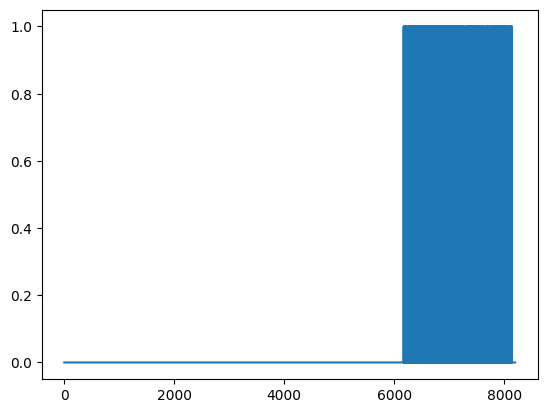

In [141]:
plt.plot(jnp.isnan(log_weighted_likelihoods).T)

In [137]:
valid_mask.shape

(1, 8200)

In [136]:
log_weighted_likelihoods.shape

(1, 8200)

In [131]:
import train

train.loss.gmm_nll(masked_y, masked_y_hat, valid_mask, None)

Array(nan, dtype=float32)

In [114]:
np.nansum(batch.y['discharge'][0,:,0])

88.6320204432597

In [ ]:
obs_emb['swot-river'][0].shape

In [ ]:
batch.dynamic['swot-river'].shape

In [ ]:
sub_m

In [ ]:
batch.dynamic['swot-river'][:, batch.node_mask, :]

In [ ]:
batch.node_mask[None,:,None].shape